<a href="https://colab.research.google.com/github/erica-teoh/stargazers-log/blob/main/MMA3001_CO2_Reconstruction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 Project — Reconstruction of Missing Indoor CO₂ Sensor Measurements

This project investigates the reconstruction of missing indoor CO₂ sensor measurements using numerical interpolation and machine-learning methods.

The primary engineering question is:

How accurately can missing CO₂ measurements be reconstructed using numerical interpolation and machine-learning methods, and how does reconstruction performance change as the duration of missing data increases?

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import glob
import pandas as pd
import numpy as np
import json

filename = "5EnvSensor_MayToDec2024_180kRows.csv"

matches = glob.glob(
    f"/content/drive/MyDrive/**/{filename}",
    recursive=True
)

print("Files found:")
print(matches)

Files found:
['/content/drive/MyDrive/MMA3001 Project/5EnvSensor_MayToDec2024_180kRows.csv']


In [3]:
file_path = matches[0]

raw_df = pd.read_csv(file_path)

print("Dataset shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())

raw_df.head()

Dataset shape: (179447, 8)

Columns:
['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [7]:
def unpack_sensor_row(json_string):
    """
    Extract environmental sensor measurements from one JSON record.
    Missing measurements are stored as NaN rather than causing an error.
    """

    data = json.loads(json_string)

    output = {}
    measurement_times = []

    for item in data:

        variable_name = item["variable"]["name"]
        values = item.get("values", [])

        if len(values) > 0:

            # Some entries contain a timestamp but no measurement value
            output[variable_name] = values[0].get("value", np.nan)

            if "time" in values[0]:
                measurement_times.append(values[0]["time"])

    if measurement_times:
        output["measurement_time"] = measurement_times[0]

    return output


parsed_measurements = pd.DataFrame(
    raw_df["jsondata"]
    .apply(unpack_sensor_row)
    .tolist()
)

parsed_measurements["sensorid"] = raw_df["sensorid"].values

parsed_measurements.head()

,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10,measurement_time,sensorid
0,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0,1702273965,6012002000241
1,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0,1702273965,6012002000241
2,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0,1702270857,6012002000326
3,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0,1683326565,6012002000777
4,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0,1709186696,6012002000869


In [8]:
sensor_counts = parsed_measurements["sensorid"].value_counts()

print(sensor_counts)

sensorid
6012002000326    58909
6012002000241    58908
6012002000869    29341
6012002000227    21363
6012002000777    10926
Name: count, dtype: int64


In [9]:
#isolate chosen sensor

SENSOR_ID = 6012002000869

sensor_df = parsed_measurements[
    parsed_measurements["sensorid"] == SENSOR_ID
].copy()

sensor_df["timestamp"] = pd.to_datetime(
    sensor_df["measurement_time"],
    unit="s",
    utc=True
)

sensor_df["timestamp"] = sensor_df["timestamp"].dt.tz_convert(
    "Australia/Melbourne"
)

sensor_df = sensor_df.sort_values("timestamp")

print("Raw rows for selected sensor:", len(sensor_df))
print("Start:", sensor_df["timestamp"].min())
print("End:", sensor_df["timestamp"].max())

sensor_df.head()

Raw rows for selected sensor: 29341
Start: 2024-02-29 17:04:56+11:00
End: 2024-06-14 03:45:44+10:00


,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10,measurement_time,sensorid,timestamp
4,4.125,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0,1709186696,6012002000869,2024-02-29 17:04:56+11:00
8,4.125,445,56,17.0,1010,24.0,0.0,2.0,5.0,4.0,5.0,1709187297,6012002000869,2024-02-29 17:14:57+11:00
12,4.125,471,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,2.0,1709188497,6012002000869,2024-02-29 17:34:57+11:00
16,4.125,457,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,3.0,1709189097,6012002000869,2024-02-29 17:44:57+11:00
20,4.125,455,57,17.0,1010,23.8,0.0,1.0,2.0,2.0,2.0,1709189697,6012002000869,2024-02-29 17:54:57+11:00


In [10]:
#removing duplicate timestamps

clean_df = sensor_df.drop_duplicates(
    subset="measurement_time",
    keep="first"
).copy()

clean_df = clean_df.sort_values("timestamp").reset_index(drop=True)

print("Rows before duplicate removal:", len(sensor_df))
print("Rows after duplicate removal:", len(clean_df))
print("Duplicates removed:", len(sensor_df) - len(clean_df))

print("\nDate range:")
print(clean_df["timestamp"].min())
print("to")
print(clean_df["timestamp"].max())

Rows before duplicate removal: 29341
Rows after duplicate removal: 13800
Duplicates removed: 15541

Date range:
2024-02-29 17:04:56+11:00
to
2024-06-14 03:45:44+10:00


In [11]:
time_difference = clean_df["timestamp"].diff()

interval_minutes = time_difference.dt.total_seconds() / 60

print(interval_minutes.describe())

print("\nMost common sampling intervals:")
print(interval_minutes.round().value_counts().head(10))

count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: timestamp, dtype: float64

Most common sampling intervals:
timestamp
10.0    12409
20.0     1389
30.0        1
Name: count, dtype: int64


In [12]:
print("Missing CO2 values:")
print(clean_df["Carbon dioxide"].isna().sum())

print("\nCO2 summary:")
print(clean_df["Carbon dioxide"].describe())

Missing CO2 values:
0

CO2 summary:
count    13800.000000
mean       473.985217
std         39.403080
min        403.000000
25%        444.000000
50%        463.000000
75%        494.000000
max        646.000000
Name: Carbon dioxide, dtype: float64


## Stage 2 — Exploratory Data Analysis

In [13]:
print("Clean dataset shape:", clean_df.shape)

print("\nCO2 statistics:")
print(clean_df["Carbon dioxide"].describe())

print("\nMissing values:")
print(clean_df.isna().sum())

Clean dataset shape: (13800, 14)

CO2 statistics:
count    13800.000000
mean       473.985217
std         39.403080
min        403.000000
25%        444.000000
50%        463.000000
75%        494.000000
max        646.000000
Name: Carbon dioxide, dtype: float64

Missing values:
Battery                             0
Carbon dioxide                      0
Humidity                            0
Formaldehyde                        1
Pressure                            0
Temperature                         0
Light Volatile Organic Compounds    0
Particulate matter 1                0
Particulate matter 4                0
Particulate matter 2.5              0
Particulate matter 10               0
measurement_time                    0
sensorid                            0
timestamp                           0
dtype: int64


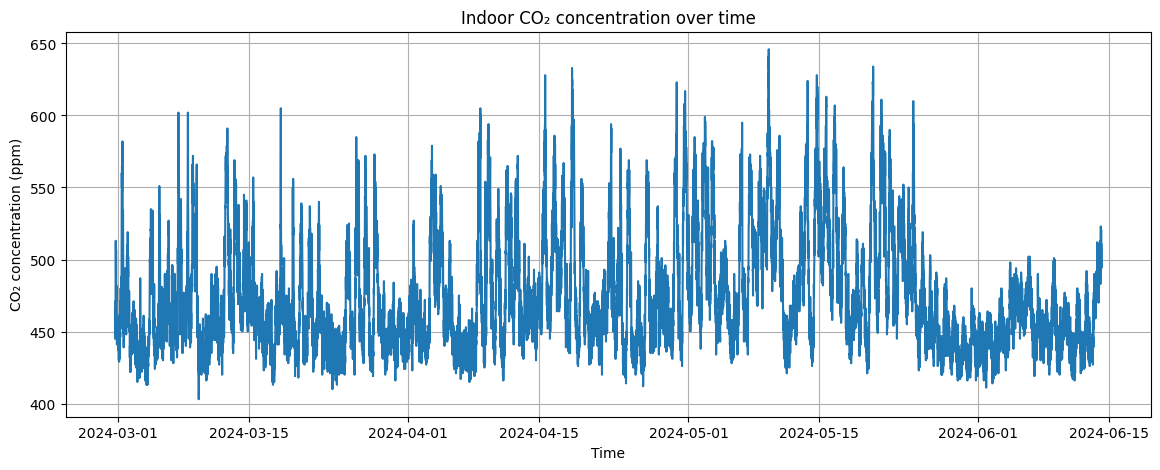

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(clean_df["timestamp"], clean_df["Carbon dioxide"])

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Indoor CO₂ concentration over time")

plt.grid(True)
plt.show()

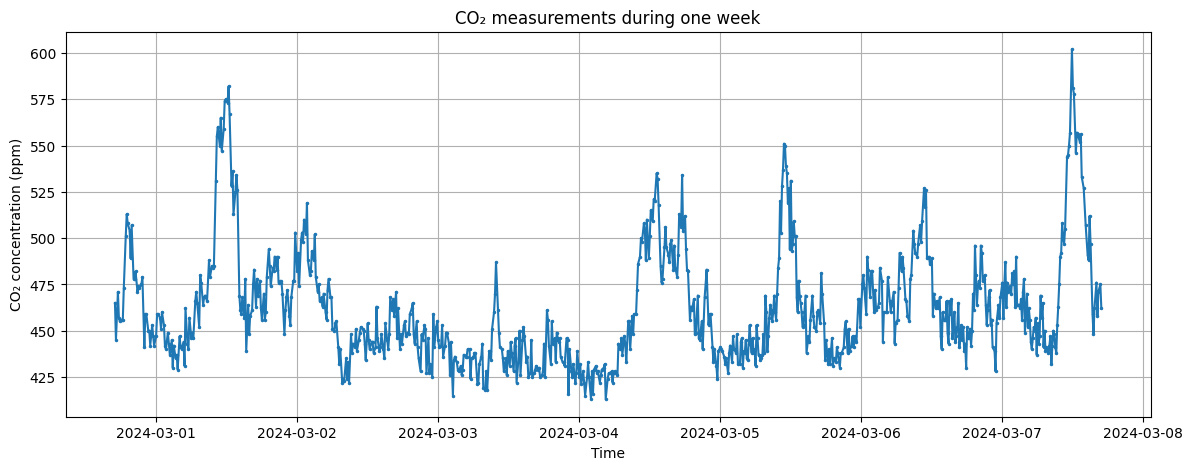

In [15]:
week_start = clean_df["timestamp"].min()
week_end = week_start + pd.Timedelta(days=7)

week_df = clean_df[
    (clean_df["timestamp"] >= week_start) &
    (clean_df["timestamp"] <= week_end)
]

plt.figure(figsize=(14, 5))
plt.plot(
    week_df["timestamp"],
    week_df["Carbon dioxide"],
    marker=".",
    markersize=3
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("CO₂ measurements during one week")

plt.grid(True)
plt.show()

In [16]:
interval_minutes = (
    clean_df["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

print("Sampling interval statistics:")
print(interval_minutes.describe())

print("\nMost common sampling intervals:")
print(interval_minutes.round().value_counts().head(10))

Sampling interval statistics:
count    13799.000000
mean        11.008102
std          3.013253
min          9.566667
25%         10.000000
50%         10.000000
75%         10.000000
max         29.983333
Name: timestamp, dtype: float64

Most common sampling intervals:
timestamp
10.0    12409
20.0     1389
30.0        1
Name: count, dtype: int64


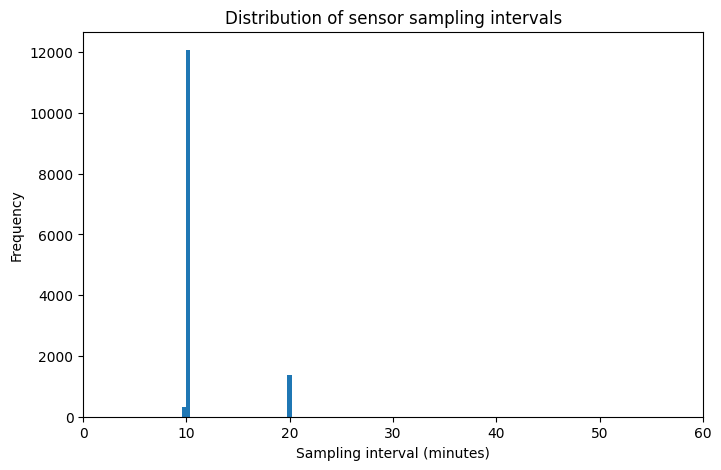

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    interval_minutes.dropna(),
    bins=50
)

plt.xlabel("Sampling interval (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of sensor sampling intervals")

plt.xlim(0, 60)

plt.show()

In [18]:
numeric_columns = [
    "Carbon dioxide",
    "Temperature",
    "Humidity",
    "Pressure",
    "Light Volatile Organic Compounds",
    "Particulate matter 1",
    "Particulate matter 2.5",
    "Particulate matter 4",
    "Particulate matter 10"
]

correlations = (
    clean_df[numeric_columns]
    .corr()["Carbon dioxide"]
    .sort_values(ascending=False)
)

print(correlations)

Carbon dioxide                      1.000000
Pressure                            0.304985
Temperature                         0.170572
Light Volatile Organic Compounds    0.042331
Humidity                            0.010713
Particulate matter 1               -0.075531
Particulate matter 2.5             -0.078499
Particulate matter 4               -0.079480
Particulate matter 10              -0.079563
Name: Carbon dioxide, dtype: float64


### Preliminary EDA observations

The cleaned dataset contains 13,800 CO₂ observations with no missing CO₂ measurements. CO₂ concentration ranges from 403 to 646 ppm, with a mean of approximately 474 ppm.

The sensor is sampled predominantly at approximately 10-minute intervals, although approximately 20-minute intervals also occur. This irregularity will be considered when constructing artificial missing-data gaps.

The CO₂ time series exhibits both relatively smooth periods and rapid transient peaks. This suggests that interpolation may perform well for short, smooth gaps but may struggle when missing intervals contain rapid changes.

Linear correlations between CO₂ and the other environmental variables are generally weak. Pressure shows the strongest positive correlation (approximately 0.305), followed by temperature (approximately 0.171). Therefore, machine-learning methods will be evaluated empirically rather than assuming that the environmental variables provide strong predictive information.

## Stage 3 — Experimental Design and Artificial Missing-Data Gaps

In [20]:
# Use the first 70% of the time series for ML model development
# and the final 30% for reconstruction experiments.

split_index = int(0.70 * len(clean_df))

train_df = clean_df.iloc[:split_index].copy()

evaluation_df = (
    clean_df.iloc[split_index:]
    .copy()
    .reset_index()
    .rename(columns={"index": "original_index"})
)

print("Training observations:", len(train_df))
print("Evaluation observations:", len(evaluation_df))

print("\nTraining period:")
print(train_df["timestamp"].min(), "to", train_df["timestamp"].max())

print("\nEvaluation period:")
print(evaluation_df["timestamp"].min(), "to", evaluation_df["timestamp"].max())

Training observations: 9660
Evaluation observations: 4140

Training period:
2024-02-29 17:04:56+11:00 to 2024-05-14 08:55:31+10:00

Evaluation period:
2024-05-14 09:05:31+10:00 to 2024-06-14 03:45:44+10:00


In [21]:
evaluation_df["interval_minutes"] = (
    evaluation_df["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

# Treat intervals from 9 to 11 minutes as nominal 10-minute sampling
evaluation_df["regular_interval"] = (
    evaluation_df["interval_minutes"]
    .between(9, 11)
)

print(evaluation_df["regular_interval"].value_counts())

print(
    "\nPercentage of evaluation intervals approximately 10 minutes:",
    100 * evaluation_df["regular_interval"].mean()
)

regular_interval
True     3846
False     294
Name: count, dtype: int64

Percentage of evaluation intervals approximately 10 minutes: 92.89855072463769


In [28]:
import numpy as np
import pandas as pd
# Gap lengths expressed as number of expected 10-minute measurements
GAP_SIZES = {
    10: 1,
    30: 3,
    60: 6,
    120: 12
}

N_TRIALS = 100
RANDOM_SEED = 3001

rng = np.random.default_rng(RANDOM_SEED)

# Find locations capable of supporting the LONGEST gap.
# These locations will then be used for every gap duration.

max_missing = max(GAP_SIZES.values())

common_valid_starts = []

for start in range(1, len(evaluation_df) - max_missing):

    end = start + max_missing - 1

    required_edges = evaluation_df.loc[
        start:end + 1,
        "regular_interval"
    ]

    if required_edges.all():
        common_valid_starts.append(start)


print(
    "Locations suitable for every gap duration:",
    len(common_valid_starts)
)

if len(common_valid_starts) < N_TRIALS:
    raise ValueError("Not enough common locations for the experiment.")


# Same 100 locations used for every method and every gap duration
selected_starts = rng.choice(
    common_valid_starts,
    size=N_TRIALS,
    replace=False
)


gap_trials = []

for gap_minutes, n_missing in GAP_SIZES.items():

    for trial_number, start in enumerate(selected_starts, start=1):

        end = start + n_missing - 1

        gap_trials.append({
            "trial": trial_number,
            "gap_minutes": gap_minutes,
            "n_missing": n_missing,
            "start_position": int(start),
            "end_position": int(end),
            "start_time": evaluation_df.loc[start, "timestamp"],
            "end_time": evaluation_df.loc[end, "timestamp"]
        })


gap_trials = pd.DataFrame(gap_trials)

print("\nTotal experiments:", len(gap_trials))

print("\nExperiments by gap duration:")
print(
    gap_trials["gap_minutes"]
    .value_counts()
    .sort_index()
)

gap_trials.head()

Locations suitable for every gap duration: 338

Total experiments: 400

Experiments by gap duration:
gap_minutes
10     100
30     100
60     100
120    100
Name: count, dtype: int64


,trial,gap_minutes,n_missing,start_position,end_position,start_time,end_time
0,1,10,1,3364,3364,2024-06-08 09:45:42+10:00,2024-06-08 09:45:42+10:00
1,2,10,1,2314,2314,2024-05-31 14:35:35+10:00,2024-05-31 14:35:35+10:00
2,3,10,1,1262,1262,2024-05-23 19:15:34+10:00,2024-05-23 19:15:34+10:00
3,4,10,1,1277,1277,2024-05-23 21:55:35+10:00,2024-05-23 21:55:35+10:00
4,5,10,1,1570,1570,2024-05-26 02:05:35+10:00,2024-05-26 02:05:35+10:00


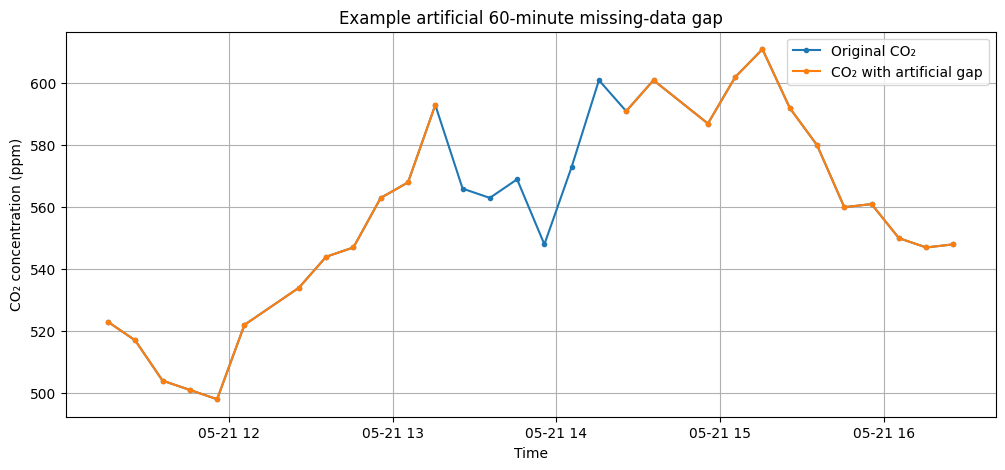

In [23]:
example_trial = gap_trials[
    gap_trials["gap_minutes"] == 60
].iloc[0]

start = int(example_trial["start_position"])
end = int(example_trial["end_position"])

example_df = evaluation_df.copy()

# Save the true values
true_values = example_df.loc[
    start:end,
    "Carbon dioxide"
].copy()

# Artificially remove them
example_df.loc[
    start:end,
    "Carbon dioxide"
] = np.nan


plot_start = max(0, start - 12)
plot_end = min(len(example_df) - 1, end + 12)

plt.figure(figsize=(12, 5))

plt.plot(
    evaluation_df.loc[plot_start:plot_end, "timestamp"],
    evaluation_df.loc[plot_start:plot_end, "Carbon dioxide"],
    label="Original CO₂",
    marker="."
)

plt.plot(
    example_df.loc[plot_start:plot_end, "timestamp"],
    example_df.loc[plot_start:plot_end, "Carbon dioxide"],
    label="CO₂ with artificial gap",
    marker="."
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Example artificial 60-minute missing-data gap")

plt.legend()
plt.grid(True)

plt.show()

## Stage 4 — Linear interpolation baseline

In [33]:
from time import perf_counter

linear_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    # Create time-indexed CO2 series
    co2_series = pd.Series(
        evaluation_df["Carbon dioxide"].to_numpy(),
        index=evaluation_df["timestamp"]
    )

    # Ground-truth values before masking
    true_values = co2_series.iloc[start:end + 1].copy()

    # Artificially remove the chosen measurements
    masked_series = co2_series.copy()
    masked_series.iloc[start:end + 1] = np.nan

    # Time the reconstruction method
    start_timer = perf_counter()

    reconstructed = masked_series.interpolate(
        method="time",
        limit_area="inside"
    )

    runtime = perf_counter() - start_timer

    predicted_values = reconstructed.iloc[start:end + 1]

    # Store every hidden point
    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        linear_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value,
            "runtime_seconds": runtime
        })


linear_results = pd.DataFrame(linear_predictions)

linear_results.head()

,trial,gap_minutes,true_co2,predicted_co2,runtime_seconds
0,1,10,451,455.497915,0.001090
1,2,10,448,442.000000,0.000674
2,3,10,527,519.500000,0.000595
3,4,10,500,500.500000,0.000568
4,5,10,497,494.500000,0.000562


In [34]:
def calculate_metrics(group):
    true = group["true_co2"].to_numpy()
    predicted = group["predicted_co2"].to_numpy()

    errors = true - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))

    ss_res = np.sum(errors**2)
    ss_tot = np.sum((true - np.mean(true))**2)

    r2 = 1 - ss_res / ss_tot

    return pd.Series({
        "MAE_ppm": mae,
        "RMSE_ppm": rmse,
        "R2": r2
    })


linear_metrics = (
    linear_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(linear_metrics)

              MAE_ppm   RMSE_ppm        R2
gap_minutes                               
10           7.609857   9.332926  0.904649
30           7.728420   9.427681  0.902987
60           8.445527  10.578596  0.879757
120          8.828582  11.079444  0.873142


/tmp/ipykernel_1823/1638611515.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


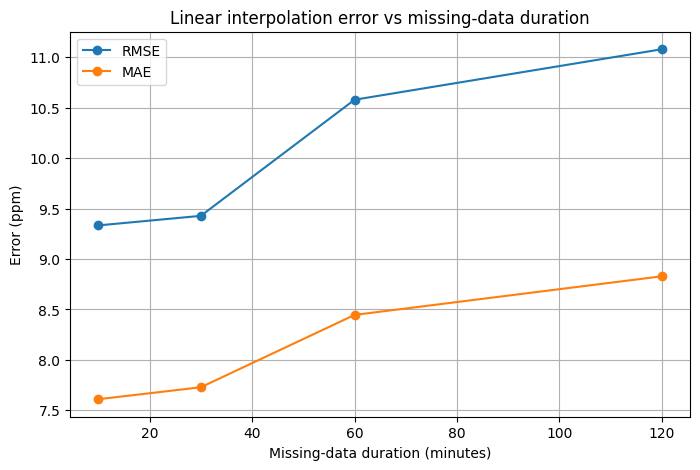

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    linear_metrics.index,
    linear_metrics["RMSE_ppm"],
    marker="o",
    label="RMSE"
)

plt.plot(
    linear_metrics.index,
    linear_metrics["MAE_ppm"],
    marker="o",
    label="MAE"
)

plt.xlabel("Missing-data duration (minutes)")
plt.ylabel("Error (ppm)")
plt.title("Linear interpolation error vs missing-data duration")

plt.legend()
plt.grid(True)

plt.show()

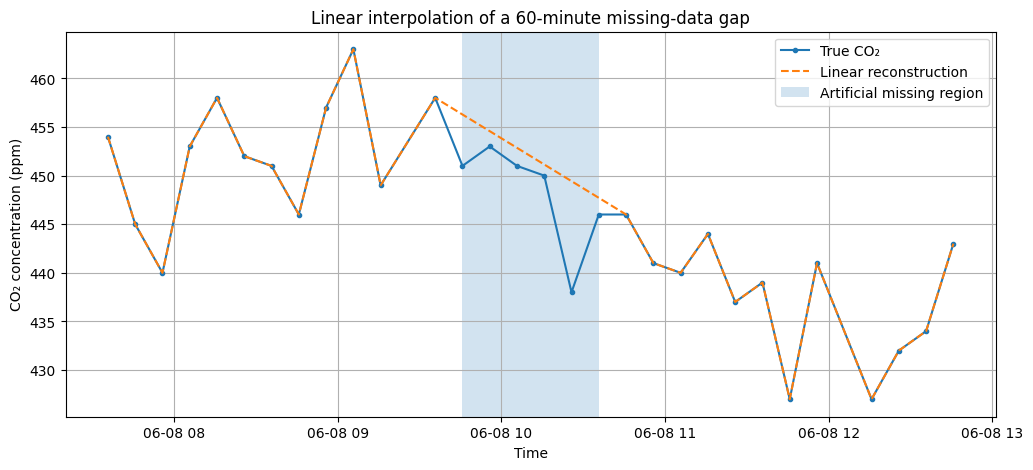

In [36]:
trial_60 = gap_trials[
    gap_trials["gap_minutes"] == 60
].iloc[0]

start = int(trial_60["start_position"])
end = int(trial_60["end_position"])

co2_series = pd.Series(
    evaluation_df["Carbon dioxide"].to_numpy(),
    index=evaluation_df["timestamp"]
)

masked_series = co2_series.copy()
masked_series.iloc[start:end + 1] = np.nan

linear_reconstruction = masked_series.interpolate(
    method="time",
    limit_area="inside"
)

plot_start = max(0, start - 12)
plot_end = min(len(evaluation_df) - 1, end + 12)

plt.figure(figsize=(12, 5))

plt.plot(
    co2_series.index[plot_start:plot_end + 1],
    co2_series.iloc[plot_start:plot_end + 1],
    label="True CO₂",
    marker="."
)

plt.plot(
    linear_reconstruction.index[plot_start:plot_end + 1],
    linear_reconstruction.iloc[plot_start:plot_end + 1],
    label="Linear reconstruction",
    linestyle="--"
)

plt.axvspan(
    evaluation_df.loc[start, "timestamp"],
    evaluation_df.loc[end, "timestamp"],
    alpha=0.2,
    label="Artificial missing region"
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Linear interpolation of a 60-minute missing-data gap")

plt.legend()
plt.grid(True)

plt.show()

## Stage 5 — PCHIP Interpolation

In [37]:
from scipy.interpolate import PchipInterpolator
from time import perf_counter

pchip_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    timestamps = evaluation_df["timestamp"]
    co2_values = evaluation_df["Carbon dioxide"].to_numpy()

    true_values = co2_values[start:end + 1].copy()

    # Convert timestamps to elapsed seconds
    time_seconds = (
        timestamps - timestamps.iloc[0]
    ).dt.total_seconds().to_numpy()

    known_mask = np.ones(len(co2_values), dtype=bool)
    known_mask[start:end + 1] = False

    x_known = time_seconds[known_mask]
    y_known = co2_values[known_mask]

    x_missing = time_seconds[start:end + 1]

    start_timer = perf_counter()

    pchip = PchipInterpolator(
        x_known,
        y_known,
        extrapolate=False
    )

    predicted_values = pchip(x_missing)

    runtime = perf_counter() - start_timer

    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        pchip_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value,
            "runtime_seconds": runtime
        })


pchip_results = pd.DataFrame(pchip_predictions)

pchip_results.head()

,trial,gap_minutes,true_co2,predicted_co2,runtime_seconds
0,1,10,451,456.045838,0.003416
1,2,10,448,441.266667,0.003092
2,3,10,527,518.766667,0.001002
3,4,10,500,502.293706,0.002949
4,5,10,497,494.935484,0.000940


In [38]:
pchip_metrics = (
    pchip_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(pchip_metrics)

              MAE_ppm   RMSE_ppm        R2
gap_minutes                               
10           7.822619   9.589574  0.899333
30           8.112862   9.938302  0.892193
60           9.044245  11.335077  0.861945
120          9.468940  11.839448  0.855142


/tmp/ipykernel_1823/991238228.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


In [39]:
comparison = pd.DataFrame({
    "Linear_MAE": linear_metrics["MAE_ppm"],
    "PCHIP_MAE": pchip_metrics["MAE_ppm"],
    "Linear_RMSE": linear_metrics["RMSE_ppm"],
    "PCHIP_RMSE": pchip_metrics["RMSE_ppm"],
    "Linear_R2": linear_metrics["R2"],
    "PCHIP_R2": pchip_metrics["R2"]
})

print(comparison)

             Linear_MAE  PCHIP_MAE  Linear_RMSE  PCHIP_RMSE  Linear_R2  \
gap_minutes                                                              
10             7.609857   7.822619     9.332926    9.589574   0.904649   
30             7.728420   8.112862     9.427681    9.938302   0.902987   
60             8.445527   9.044245    10.578596   11.335077   0.879757   
120            8.828582   9.468940    11.079444   11.839448   0.873142   

             PCHIP_R2  
gap_minutes            
10           0.899333  
30           0.892193  
60           0.861945  
120          0.855142  


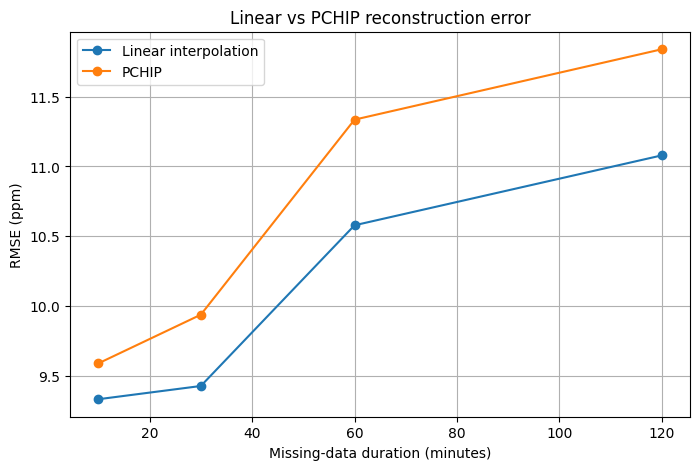

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    linear_metrics.index,
    linear_metrics["RMSE_ppm"],
    marker="o",
    label="Linear interpolation"
)

plt.plot(
    pchip_metrics.index,
    pchip_metrics["RMSE_ppm"],
    marker="o",
    label="PCHIP"
)

plt.xlabel("Missing-data duration (minutes)")
plt.ylabel("RMSE (ppm)")
plt.title("Linear vs PCHIP reconstruction error")

plt.legend()
plt.grid(True)

plt.show()

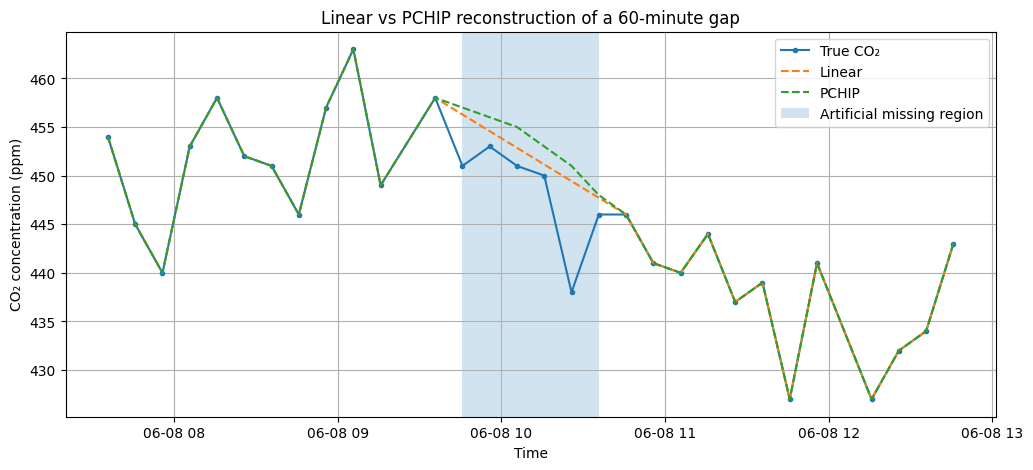

In [41]:
trial_60 = gap_trials[
    gap_trials["gap_minutes"] == 60
].iloc[0]

start = int(trial_60["start_position"])
end = int(trial_60["end_position"])

timestamps = evaluation_df["timestamp"]
co2_values = evaluation_df["Carbon dioxide"].to_numpy()

time_seconds = (
    timestamps - timestamps.iloc[0]
).dt.total_seconds().to_numpy()

known_mask = np.ones(len(co2_values), dtype=bool)
known_mask[start:end + 1] = False

pchip_model = PchipInterpolator(
    time_seconds[known_mask],
    co2_values[known_mask],
    extrapolate=False
)

pchip_full = co2_values.copy()
pchip_full[start:end + 1] = pchip_model(
    time_seconds[start:end + 1]
)

# Linear reconstruction again
co2_series = pd.Series(
    co2_values,
    index=timestamps
)

linear_series = co2_series.copy()
linear_series.iloc[start:end + 1] = np.nan

linear_series = linear_series.interpolate(
    method="time",
    limit_area="inside"
)

plot_start = max(0, start - 12)
plot_end = min(len(evaluation_df) - 1, end + 12)

plt.figure(figsize=(12, 5))

plt.plot(
    timestamps.iloc[plot_start:plot_end + 1],
    co2_values[plot_start:plot_end + 1],
    label="True CO₂",
    marker="."
)

plt.plot(
    timestamps.iloc[plot_start:plot_end + 1],
    linear_series.iloc[plot_start:plot_end + 1],
    linestyle="--",
    label="Linear"
)

plt.plot(
    timestamps.iloc[plot_start:plot_end + 1],
    pchip_full[plot_start:plot_end + 1],
    linestyle="--",
    label="PCHIP"
)

plt.axvspan(
    timestamps.iloc[start],
    timestamps.iloc[end],
    alpha=0.2,
    label="Artificial missing region"
)

plt.xlabel("Time")
plt.ylabel("CO₂ concentration (ppm)")
plt.title("Linear vs PCHIP reconstruction of a 60-minute gap")

plt.legend()
plt.grid(True)

plt.show()

### PCHIP interpretation

PCHIP was evaluated as a shape-preserving nonlinear interpolation method that is alternative to linear interpolation. However, PCHIP produced higher MAE and RMSE and lower R^2 across all tested missing data durations.

This indicates that additional interpolation curvature did not improve reconstruction of the measured CO2 signal. Both interpolation methods are limited by their reliance on surrounding CO2 measurements and therefore cannot reliably reconstruct transient behaviour occurring entirely within a missing interval.

Linear interpolation was therefore retained as the stronger interpolation baseline due to its lower reconstruction error and simpler implementation.

## Stage 6 — Decision Tree Regression

In [42]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = [
    "Temperature",
    "Humidity",
    "Pressure",
    "Light Volatile Organic Compounds",
    "Particulate matter 1",
    "Particulate matter 2.5",
    "Particulate matter 4",
    "Particulate matter 10",
    "Battery"
]

TARGET = "Carbon dioxide"

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

X_eval = evaluation_df[FEATURES].copy()

print("Training feature shape:", X_train.shape)
print("Evaluation feature shape:", X_eval.shape)

print("\nMissing training values:")
print(X_train.isna().sum())

Training feature shape: (9660, 9)
Evaluation feature shape: (4140, 9)

Missing training values:
Temperature                         0
Humidity                            0
Pressure                            0
Light Volatile Organic Compounds    0
Particulate matter 1                0
Particulate matter 2.5              0
Particulate matter 4                0
Particulate matter 10               0
Battery                             0
dtype: int64


In [43]:
tree_model = DecisionTreeRegressor(
    random_state=3001
)

tree_model.fit(X_train, y_train)

evaluation_df["tree_prediction"] = tree_model.predict(X_eval)

print("Decision Tree trained.")

Decision Tree trained.


In [44]:
tree_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    true_values = evaluation_df.loc[
        start:end,
        "Carbon dioxide"
    ].to_numpy()

    predicted_values = evaluation_df.loc[
        start:end,
        "tree_prediction"
    ].to_numpy()

    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        tree_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value
        })


tree_results = pd.DataFrame(tree_predictions)

tree_results.head()

,trial,gap_minutes,true_co2,predicted_co2
0,1,10,451,516.000000
1,2,10,448,464.000000
2,3,10,527,485.666667
3,4,10,500,485.000000
4,5,10,497,533.000000


In [45]:
tree_metrics = (
    tree_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(tree_metrics)

               MAE_ppm   RMSE_ppm        R2
gap_minutes                                
10           42.200000  54.306660 -2.228459
30           40.227222  51.375745 -1.880967
60           40.451667  52.481497 -1.959484
120          41.288889  54.220735 -2.038169


/tmp/ipykernel_1823/2107866217.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


In [46]:
method_comparison = pd.DataFrame({
    "Linear_RMSE": linear_metrics["RMSE_ppm"],
    "PCHIP_RMSE": pchip_metrics["RMSE_ppm"],
    "DecisionTree_RMSE": tree_metrics["RMSE_ppm"]
})

print(method_comparison)

             Linear_RMSE  PCHIP_RMSE  DecisionTree_RMSE
gap_minutes                                            
10              9.332926    9.589574          54.306660
30              9.427681    9.938302          51.375745
60             10.578596   11.335077          52.481497
120            11.079444   11.839448          54.220735


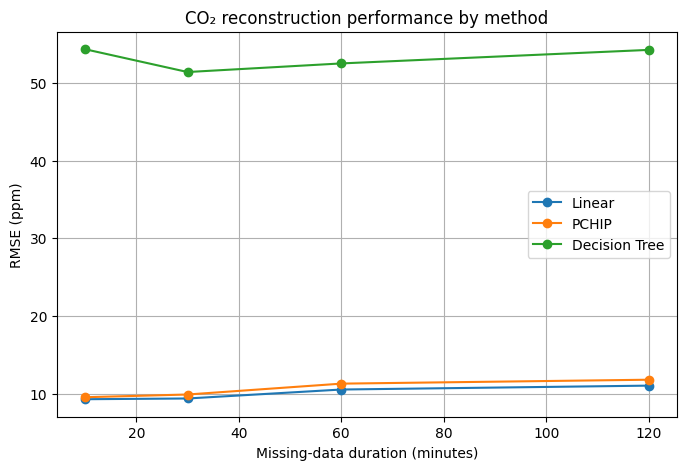

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    linear_metrics.index,
    linear_metrics["RMSE_ppm"],
    marker="o",
    label="Linear"
)

plt.plot(
    pchip_metrics.index,
    pchip_metrics["RMSE_ppm"],
    marker="o",
    label="PCHIP"
)

plt.plot(
    tree_metrics.index,
    tree_metrics["RMSE_ppm"],
    marker="o",
    label="Decision Tree"
)

plt.xlabel("Missing-data duration (minutes)")
plt.ylabel("RMSE (ppm)")
plt.title("CO₂ reconstruction performance by method")

plt.legend()
plt.grid(True)
plt.show()

### Diagnose ML failure

TRAINING CO2:
count    9660.000000
mean      475.500932
std        39.468402
min       403.000000
25%       446.000000
50%       464.000000
75%       497.000000
max       646.000000
Name: Carbon dioxide, dtype: float64

EVALUATION CO2:
count    4140.000000
mean      470.448551
std        39.026682
min       411.000000
25%       442.000000
50%       459.000000
75%       487.000000
max       634.000000
Name: Carbon dioxide, dtype: float64


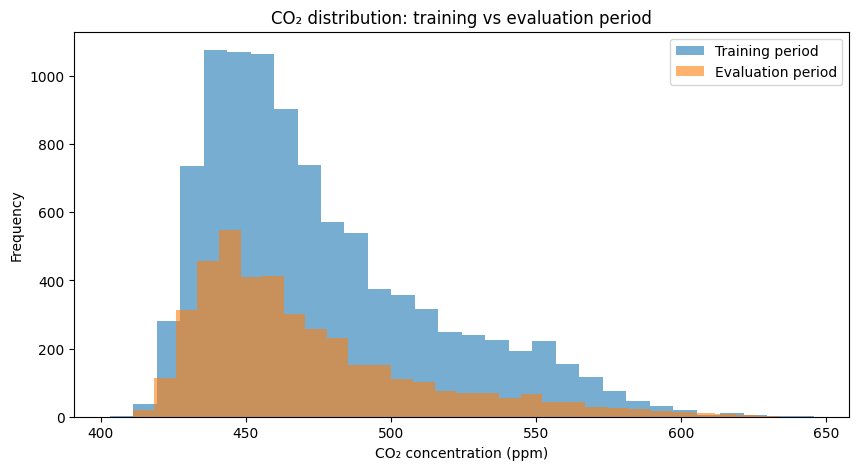

In [49]:
print("TRAINING CO2:")
print(train_df["Carbon dioxide"].describe())

print("\nEVALUATION CO2:")
print(evaluation_df["Carbon dioxide"].describe())

plt.figure(figsize=(10, 5))

plt.hist(
    train_df["Carbon dioxide"],
    bins=30,
    alpha=0.6,
    label="Training period"
)

plt.hist(
    evaluation_df["Carbon dioxide"],
    bins=30,
    alpha=0.6,
    label="Evaluation period"
)

plt.xlabel("CO₂ concentration (ppm)")
plt.ylabel("Frequency")
plt.title("CO₂ distribution: training vs evaluation period")

plt.legend()
plt.show()

In [50]:
feature_comparison = pd.DataFrame({
    "Train_mean": train_df[FEATURES].mean(),
    "Eval_mean": evaluation_df[FEATURES].mean(),
    "Train_std": train_df[FEATURES].std(),
    "Eval_std": evaluation_df[FEATURES].std()
})

feature_comparison["Mean_change_%"] = (
    (feature_comparison["Eval_mean"] - feature_comparison["Train_mean"])
    / feature_comparison["Train_mean"]
    * 100
)

feature_comparison

,Train_mean,Eval_mean,Train_std,Eval_std,Mean_change_%
Temperature,23.147598,22.953986,1.172104,1.130598,-0.836427
Humidity,47.341718,39.648792,7.069025,4.922824,-16.249782
Pressure,1017.659834,1018.213043,5.600037,5.783316,0.054361
Light Volatile Organic Compounds,5.711284,21.536473,24.224632,51.293846,277.086392
Particulate matter 1,4.227226,1.859179,8.002150,1.895742,-56.018938
Particulate matter 2.5,5.506418,2.847101,8.908100,2.402896,-48.294856
Particulate matter 4,6.389855,3.616184,9.398406,2.999844,-43.407424
Particulate matter 10,6.565217,3.765700,9.506412,3.139917,-42.641648
Battery,4.096996,4.060875,0.013244,0.007014,-0.881666


In [51]:
internal_split = int(0.80 * len(train_df))

model_train_df = train_df.iloc[:internal_split].copy()
validation_df = train_df.iloc[internal_split:].copy()

X_model_train = model_train_df[FEATURES]
y_model_train = model_train_df[TARGET]

X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

print("Model-training rows:", len(model_train_df))
print("Validation rows:", len(validation_df))

print("\nModel-training period:")
print(
    model_train_df["timestamp"].min(),
    "to",
    model_train_df["timestamp"].max()
)

print("\nValidation period:")
print(
    validation_df["timestamp"].min(),
    "to",
    validation_df["timestamp"].max()
)

Model-training rows: 7728
Validation rows: 1932

Model-training period:
2024-02-29 17:04:56+11:00 to 2024-04-29 21:55:23+10:00

Validation period:
2024-04-29 22:05:23+10:00 to 2024-05-14 08:55:31+10:00


In [52]:
tree_tuning_results = []

for depth in [2, 3, 4, 5, 6, 8, 10, 15, None]:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=3001
    )

    model.fit(
        X_model_train,
        y_model_train
    )

    validation_predictions = model.predict(X_validation)

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            validation_predictions
        )
    )

    mae = mean_absolute_error(
        y_validation,
        validation_predictions
    )

    tree_tuning_results.append({
        "max_depth": depth,
        "Validation_RMSE": rmse,
        "Validation_MAE": mae
    })


tree_tuning_results = pd.DataFrame(tree_tuning_results)

tree_tuning_results

,max_depth,Validation_RMSE,Validation_MAE
0,2.0,48.197768,37.964901
1,3.0,47.213789,37.244289
2,4.0,46.847751,37.069903
3,5.0,55.016057,43.169817
4,6.0,56.021674,43.890279
5,8.0,57.222956,44.382357
6,10.0,57.998102,45.556527
7,15.0,59.347716,47.139967
8,NaN,61.688538,49.263051


### Decision Tree optimisation and distribution shift

The untuned Decision Tree performed substantially worse than the interpolation methods.

The CO2 target distributions in the training and evaluation periods were widely similar. However between the two periods, several predictor variables changed considerably. For eg, mean VOC increased by approximately 277%, while particulate-matter variables decreased by approximately 43–56%. This indicates distribution shift between the model-development and evaluation periods.

A time-ordered internal validation set was therefore used to tune Decision Tree depth without accessing the final evaluation period. Validation RMSE was minimised at a maximum tree depth of 4 (approximately 46.85 ppm). Increasing tree depth beyond this point increased validation error substantially, indicating overfitting.

The tuned depth of 4 was therefore selected for final evaluation.

### Stage 6C - Evaluate the tuned Decision Tree

In [53]:
tuned_tree = DecisionTreeRegressor(
    max_depth=4,
    random_state=3001
)

tuned_tree.fit(
    train_df[FEATURES],
    train_df[TARGET]
)

evaluation_df["tuned_tree_prediction"] = tuned_tree.predict(
    evaluation_df[FEATURES]
)

print("Tuned Decision Tree trained using max_depth = 4.")

Tuned Decision Tree trained using max_depth = 4.


In [54]:
tuned_tree_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    true_values = evaluation_df.loc[
        start:end,
        "Carbon dioxide"
    ].to_numpy()

    predicted_values = evaluation_df.loc[
        start:end,
        "tuned_tree_prediction"
    ].to_numpy()

    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        tuned_tree_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value
        })


tuned_tree_results = pd.DataFrame(tuned_tree_predictions)

tuned_tree_metrics = (
    tuned_tree_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(tuned_tree_metrics)

               MAE_ppm   RMSE_ppm        R2
gap_minutes                                
10           29.967542  37.428872 -0.533566
30           30.358787  38.410106 -0.610323
60           30.949607  39.259709 -0.656142
120          31.376249  40.158992 -0.666659


/tmp/ipykernel_1823/1783480257.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


In [55]:
tree_optimisation_comparison = pd.DataFrame({
    "Untuned_RMSE": tree_metrics["RMSE_ppm"],
    "Tuned_RMSE": tuned_tree_metrics["RMSE_ppm"]
})

print(tree_optimisation_comparison)

             Untuned_RMSE  Tuned_RMSE
gap_minutes                          
10              54.306660   37.428872
30              51.375745   38.410106
60              52.481497   39.259709
120             54.220735   40.158992


## Stage 7 — Support Vector Regression

In [57]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

scaler = StandardScaler()

X_model_train_scaled = scaler.fit_transform(X_model_train)
X_validation_scaled = scaler.transform(X_validation)

In [58]:
svr_tuning_results = []

parameter_sets = [
    {"kernel": "rbf", "C": 1, "epsilon": 0.1},
    {"kernel": "rbf", "C": 10, "epsilon": 0.1},
    {"kernel": "rbf", "C": 100, "epsilon": 0.1},
    {"kernel": "rbf", "C": 10, "epsilon": 1},
    {"kernel": "rbf", "C": 10, "epsilon": 5},
    {"kernel": "linear", "C": 1, "epsilon": 0.1},
    {"kernel": "linear", "C": 10, "epsilon": 0.1}
]

for params in parameter_sets:

    model = SVR(
        kernel=params["kernel"],
        C=params["C"],
        epsilon=params["epsilon"]
    )

    model.fit(
        X_model_train_scaled,
        y_model_train
    )

    validation_predictions = model.predict(
        X_validation_scaled
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            validation_predictions
        )
    )

    mae = mean_absolute_error(
        y_validation,
        validation_predictions
    )

    svr_tuning_results.append({
        "kernel": params["kernel"],
        "C": params["C"],
        "epsilon": params["epsilon"],
        "Validation_RMSE": rmse,
        "Validation_MAE": mae
    })


svr_tuning_results = pd.DataFrame(svr_tuning_results)

svr_tuning_results.sort_values("Validation_RMSE")

,kernel,C,epsilon,Validation_RMSE,Validation_MAE
6,linear,10,0.1,50.946119,39.502552
5,linear,1,0.1,50.950082,39.504619
0,rbf,1,0.1,54.052600,42.447359
4,rbf,10,5.0,56.388132,44.345082
3,rbf,10,1.0,56.841977,44.752621
1,rbf,10,0.1,56.986463,44.885751
2,rbf,100,0.1,59.745361,46.601146


### SVR hyperparameter selection

Support Vector Regression was evaluated using both linear and RBF kernels after standardising the predictor variables.

The lowest validation RMSE was obtained using a linear kernel with C = 10 and epsilon = 0.1, producing an RMSE of approximately 50.95 ppm. A linear model with C = 1 produced almost identical performance, while all tested RBF configurations performed worse.

These results indicate that increasing nonlinear model complexity did not improve generalisation. The linear SVR configuration with C = 10 and epsilon = 0.1 was therefore selected for final evaluation.

### Stage 7B — Final SVR evaluation

In [59]:
final_scaler = StandardScaler()

X_train_scaled = final_scaler.fit_transform(
    train_df[FEATURES]
)

X_eval_scaled = final_scaler.transform(
    evaluation_df[FEATURES]
)

final_svr = SVR(
    kernel="linear",
    C=10,
    epsilon=0.1
)

final_svr.fit(
    X_train_scaled,
    train_df[TARGET]
)

evaluation_df["svr_prediction"] = final_svr.predict(
    X_eval_scaled
)

print("Final SVR trained.")

Final SVR trained.


In [60]:
svr_predictions = []

for _, trial in gap_trials.iterrows():

    start = int(trial["start_position"])
    end = int(trial["end_position"])

    true_values = evaluation_df.loc[
        start:end,
        "Carbon dioxide"
    ].to_numpy()

    predicted_values = evaluation_df.loc[
        start:end,
        "svr_prediction"
    ].to_numpy()

    for true_value, predicted_value in zip(
        true_values,
        predicted_values
    ):
        svr_predictions.append({
            "trial": int(trial["trial"]),
            "gap_minutes": int(trial["gap_minutes"]),
            "true_co2": true_value,
            "predicted_co2": predicted_value
        })


svr_results = pd.DataFrame(svr_predictions)

svr_metrics = (
    svr_results
    .groupby("gap_minutes")
    .apply(calculate_metrics)
)

print(svr_metrics)

               MAE_ppm   RMSE_ppm        R2
gap_minutes                                
10           28.446267  35.399922 -0.371809
30           27.506928  34.648020 -0.310324
60           27.328884  34.261369 -0.261284
120          26.938888  33.911614 -0.188442


/tmp/ipykernel_1823/977369821.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


             Linear_RMSE  PCHIP_RMSE  TunedTree_RMSE   SVR_RMSE
gap_minutes                                                    
10              9.332926    9.589574       37.428872  35.399922
30              9.427681    9.938302       38.410106  34.648020
60             10.578596   11.335077       39.259709  34.261369
120            11.079444   11.839448       40.158992  33.911614


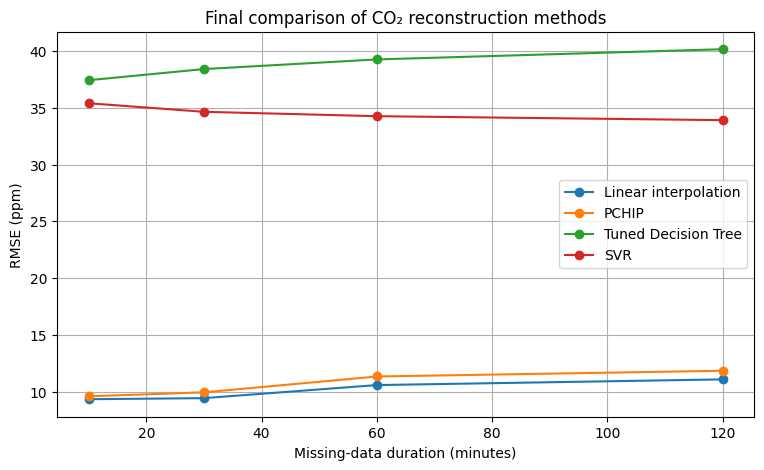

In [62]:
final_comparison = pd.DataFrame({
    "Linear_RMSE": linear_metrics["RMSE_ppm"],
    "PCHIP_RMSE": pchip_metrics["RMSE_ppm"],
    "TunedTree_RMSE": tuned_tree_metrics["RMSE_ppm"],
    "SVR_RMSE": svr_metrics["RMSE_ppm"]
})

print(final_comparison)

plt.figure(figsize=(9, 5))

plt.plot(
    linear_metrics.index,
    linear_metrics["RMSE_ppm"],
    marker="o",
    label="Linear interpolation"
)

plt.plot(
    pchip_metrics.index,
    pchip_metrics["RMSE_ppm"],
    marker="o",
    label="PCHIP"
)

plt.plot(
    tuned_tree_metrics.index,
    tuned_tree_metrics["RMSE_ppm"],
    marker="o",
    label="Tuned Decision Tree"
)

plt.plot(
    svr_metrics.index,
    svr_metrics["RMSE_ppm"],
    marker="o",
    label="SVR"
)

plt.xlabel("Missing-data duration (minutes)")
plt.ylabel("RMSE (ppm)")
plt.title("Final comparison of CO₂ reconstruction methods")

plt.legend()
plt.grid(True)

plt.show()